# **Лабораторна робота 2**
**Скалярні типи даних, побітові операції та математичне моделювання**

**Мета:** Опанувати практичні навички роботи зі скалярними типами даних мови Python (int, float, complex, bool), вивчити внутрішні особливості представлення цілих чисел довільної точності та дійсних чисел стандарту IEEE 754. Навчитися реалізовувати складні аналітичні математичні моделі із застосуванням функцій стандартних модулів math і cmath, виконувати перетворення між різними позиційними системами числення, а також освоїти бітову арифметику та маніпуляції з бітовими масками для моделювання апаратних регістрів мікроконтролерів і низькорівневих телеметричних пакетів у задачах комп'ютерної інженерії.


**Зроблено:** П'ятибрат Дмитро

**Варіант:** 16

Перша частина завдання:

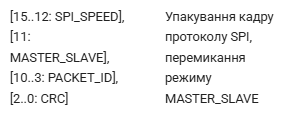

In [4]:
# Маски та зсуви для полів
SPI_SPEED_SHIFT = 12
SPI_SPEED_MASK  = 0xF  # 4 біти (0b1111)

MASTER_SLAVE_SHIFT = 11
MASTER_SLAVE_MASK  = 0x1  # 1 біт (0b1)

PACKET_ID_SHIFT = 3
PACKET_ID_MASK  = 0xFF  # 8 бітів (0b11111111)

CRC_SHIFT = 0
CRC_MASK  = 0x7  # 3 біти (0b111)

#Упаковує параметри у 16-бітний регістр.
def pack_spi_frame(spi_speed: int, master_slave: int, packet_id: int, crc: int) -> int:
    frame = (
        ((spi_speed & SPI_SPEED_MASK) << SPI_SPEED_SHIFT) |
        ((master_slave & MASTER_SLAVE_MASK) << MASTER_SLAVE_SHIFT) |
        ((packet_id & PACKET_ID_MASK) << PACKET_ID_SHIFT) |
        ((crc & CRC_MASK) << CRC_SHIFT)
    )
    return frame & 0xFFFF

#Розпаковує 16-бітний регістр на окремі поля.
def unpack_spi_frame(frame: int) -> dict:
    return {
        "SPI_SPEED": (frame >> SPI_SPEED_SHIFT) & SPI_SPEED_MASK,
        "MASTER_SLAVE": (frame >> MASTER_SLAVE_SHIFT) & MASTER_SLAVE_MASK,
        "PACKET_ID": (frame >> PACKET_ID_SHIFT) & PACKET_ID_MASK,
        "CRC": (frame >> CRC_SHIFT) & CRC_MASK,
    }

# Перемикає біт MASTER_SLAVE (11-й біт) через побітове XOR.
def toggle_master_slave(frame: int) -> int:
    return frame ^ (1 << MASTER_SLAVE_SHIFT)


# Приклад роботи
if __name__ == "__main__":
    speed = 0b1010        # 10
    mode = 1              # Master
    pkt_id = 0x5A         # 90
    crc_val = 0b011       # 3

    # Упакування
    frame = pack_spi_frame(speed, mode, pkt_id, crc_val)
    print(f"Упакований кадр (HEX): 0x{frame:04X}")
    print(f"Упакований кадр (BIN): {frame:016b}")
    print("Розпаковані поля:     ", unpack_spi_frame(frame))

    # Перемикання MASTER_SLAVE (1 -> 0)
    frame_toggled = toggle_master_slave(frame)
    print(f"\nПісля перемикання режиму: 0x{frame_toggled:04X} ({frame_toggled:016b})")
    print("Розпаковані поля:     ", unpack_spi_frame(frame_toggled))

Упакований кадр (HEX): 0xAAD3
Упакований кадр (BIN): 1010101011010011
Розпаковані поля:      {'SPI_SPEED': 10, 'MASTER_SLAVE': 1, 'PACKET_ID': 90, 'CRC': 3}

Після перемикання режиму: 0xA2D3 (1010001011010011)
Розпаковані поля:      {'SPI_SPEED': 10, 'MASTER_SLAVE': 0, 'PACKET_ID': 90, 'CRC': 3}


Друга частина завдання:

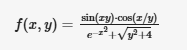

In [16]:
import math

def f(x: float, y: float) -> float:
    if y == 0:
        raise ZeroDivisionError("y не може дорівнювати 0 через ділення x/y")
    numerator = math.sin(x * y) * math.cos(x / y)
    denominator = math.exp(-(x**2)) + math.sqrt(y**2 + 4)
    return numerator / denominator

f(0.345, 1.345)

0.13126479006002487

**Контрольні запитання**

1. Цілі числа зберігаються як структура PyLongObject, що містить динамічний масив «цифр» (ob_digit) за основою $2^{30}$ (на 64-бітних системах). У C/C++ розмір змінної фіксований апаратним регістром процесора, тому виникає переповнення. У CPython при досягненні межі поточної розрядності інтерпретатор автоматично алокує новий елемент масиву в динамічній пам'яті (купі), обмежуючись лише доступною оперативною пам'яттю системи.
2. Структура: 1 біт — знак, 11 бітів — зміщена експонента (зсув 1023), 52 біти — мантиса (дробова частина).Похибка 0.1: число 0.1 у десятковій системі є нескінченним періодичним дробом у двійковій системі ($0.0001100110011..._2$), тому воно обрізається до 53 бітів точності.Порівняння: замість строгої рівності == використовують math.isclose(a, b, rel_tol=1e-9, abs_tol=0.0), яка перевіряє умову $\vert{}a - b\vert{} \le \max(\text{rel\_tol} \cdot \max(\vert{}a\vert{}, \vert{}b\vert{}), \text{abs\_tol})$.
3. Математично операція визначається формулою $\sim x = -(x + 1)$ через використання додаткового коду (two's complement) з нескінченним розширенням знакового біта.Вираз ~0: згідно з формулою $\sim 0 = -(0 + 1) = -1$ (у нескінченному двійковому представленні це нескінченний ланцюг одиниць ...11111111).Маскування: оскільки у Python немає фіксованої апаратної розрядності, інверсія додає нескінченний знаковий хвіст одиниць зліва; операція & 0xFFFF явно відсікає всі біти вище 16-го, приводячи число до беззнакового діапазону $[0, 65535]$.
4. Встановлення в одиницю: reg |= (1 << k) (побітове АБО з бітовою маскою).Скидання в нуль: reg &= ~(1 << k) (побітове І з інвертованою маскою).Інвертування: reg ^= (1 << k) (побітове виключне АБО).
5. math.sqrt(-4) викликає виняток ValueError: math domain error, оскільки модуль math працює виключно в полі дійсних чисел.cmath.sqrt(-4) повертає комплексне число 2j (або 0+2j), оскільки модуль cmath реалізований для комплексної площини.
6. Формула упакування (розташування зліва направо: A [15..12], B [11..6], C [5..0]):Word = ((A & 0x0F) << 12) | ((B & 0x3F) << 6) | (C & 0x3F)Розпакування поля B:Спочатку виділення маскою і зсув: B = (Word >> 6) & 0x3F(або з маскою за місцем: B = (Word & 0x0FC0) >> 6, де маска 0x0FC0 у двійковому вигляді дорівнює 0000 1111 1100 0000).